# <br><center>**Dimensionality Reduction of Movie Embeddings**

In [1]:
# integrations
import sys, os, json
from dotenv import load_dotenv; load_dotenv()
print(f"workdir: {os.getcwd()}")

import tmdbsimple as tmdb
import pandas as pd
import numpy as np

from google import genai
print(f"Google GenAI version: {genai.__version__}")

import matplotlib.pyplot as plt
plt.style.use("dark_background")
plt.rcParams.update({
    "figure.figsize": (30,18),
    "font.size": 14,
    "axes.grid": True,
    "grid.alpha": 0.2
})

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

workdir: /Users/daniel/creative/projects/movie-clusters
Google GenAI version: 2.33.0


In [2]:
# load embeddings
embeddings = np.load("./src/data/embeddings.npy"); embeddings

array([[ 2.4904702e-03,  3.3792146e-02,  5.8637224e-03, ...,
        -6.6091790e-03, -1.1565902e-02, -7.7381080e-03],
       [-1.8347852e-02,  2.9065318e-02,  1.1676992e-02, ...,
        -1.3782549e-02, -3.9863386e-03, -1.5772710e-02],
       [-1.3598282e-02,  2.0657560e-02,  1.4887875e-02, ...,
        -1.7578170e-03, -1.6203824e-03, -8.2852130e-03],
       ...,
       [ 6.0192902e-05,  1.6074894e-02,  2.7360609e-02, ...,
         2.1003361e-03, -4.9244114e-03,  2.1513812e-03],
       [-7.8958770e-03,  4.2494573e-02,  9.8311140e-03, ...,
        -1.8288447e-02,  6.4083503e-04, -3.1699645e-03],
       [-1.2480649e-02,  1.7542403e-02,  2.2920119e-02, ...,
        -9.7905560e-03, -9.2352140e-03, -1.8246388e-02]],
      shape=(1735, 3072))

In [7]:
# embeddings ---> 3072 -- pca -> 50 -- t-sne -> 2
embeddings_pca = PCA(n_components=50, random_state=67).fit_transform(embeddings)
embeddings_tsne = TSNE(
    n_components=2, perplexity=30,
    init="pca", random_state=67
).fit_transform(embeddings_pca)

embeddings_tsne.shape

(1735, 2)

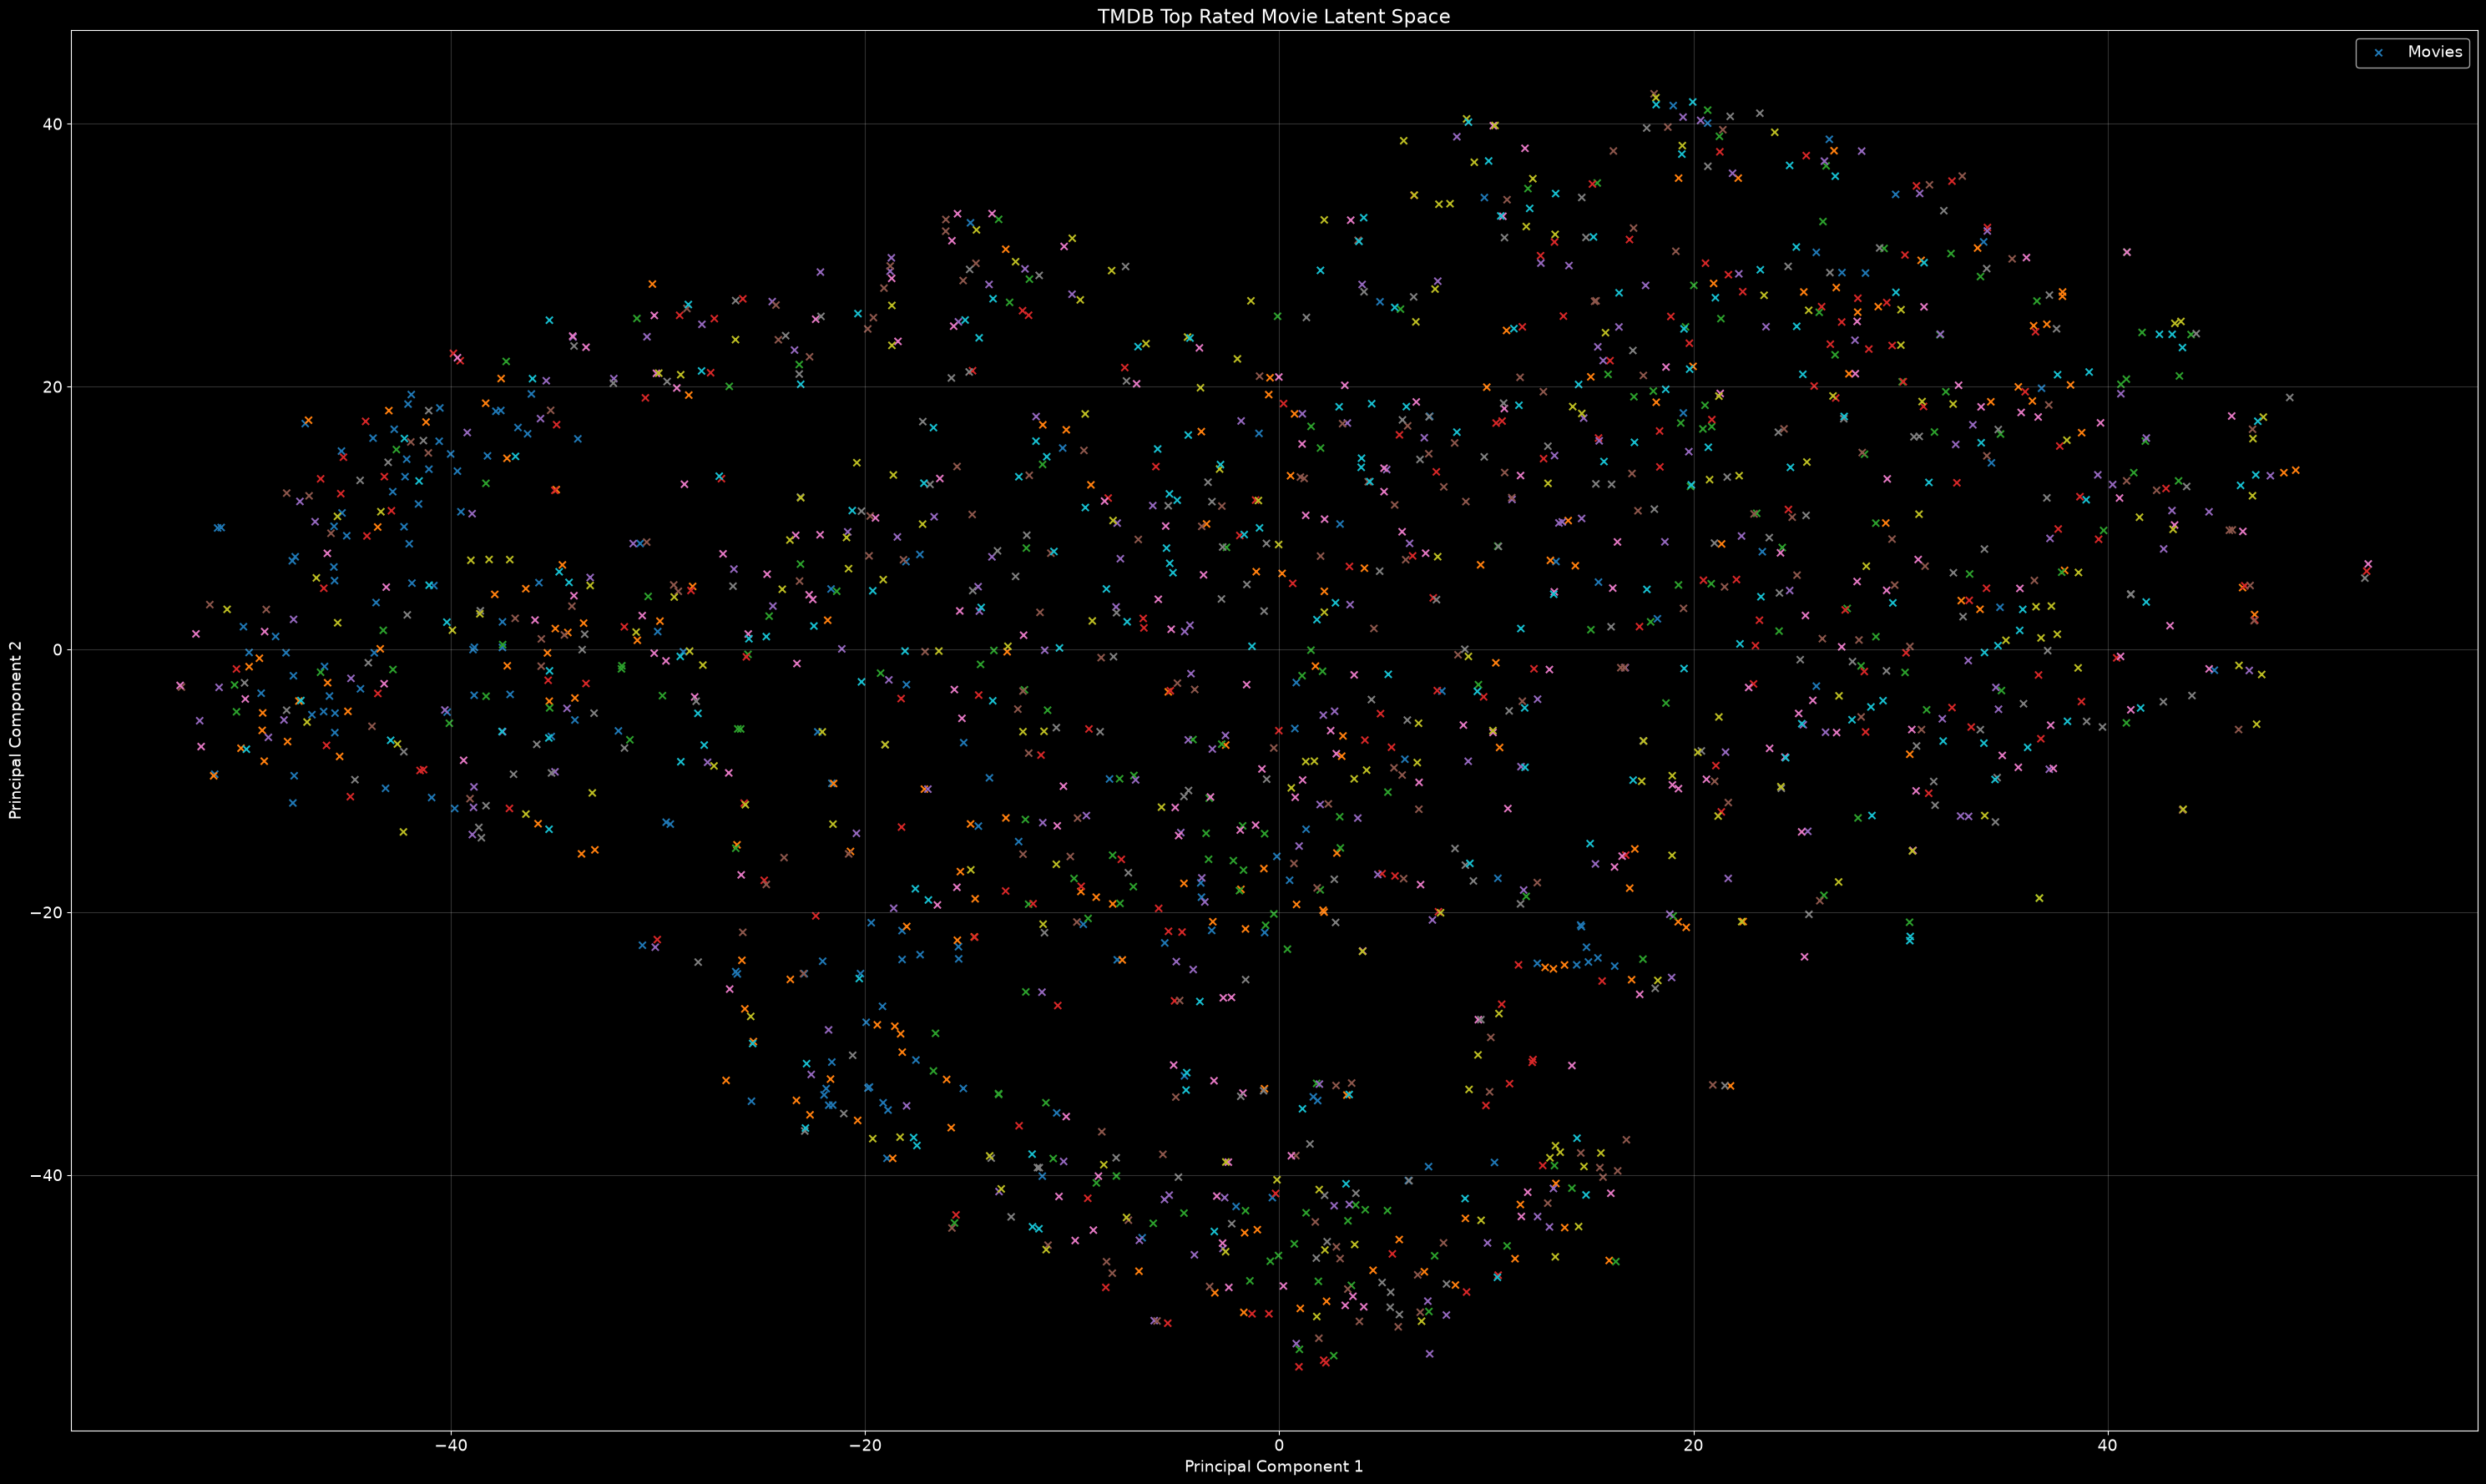

In [ ]:
# scatterplot
if int(os.getenv("MAKEPLOT1")):

    n_plot = int(os.environ.get("N_PLOT", 100))
    tsne1 = embeddings_tsne[:,0]
    tsne2 = embeddings_tsne[:,1]

    with open("./src/data/embeddings-tsne1.npy", "wb") as f:
        np.save(f, tsne1)
    with open("./src/data/embeddings-tsne2.npy", "wb") as f:
        np.save(f, tsne2)

    # scatter projected embeddings
    plt.scatter(tsne1[:n_plot], tsne2[:n_plot], marker="x", label="Movies", cmap="tab10", c=np.arange(n_plot))

    # add movie titles
    if int(os.getenv("MOVIE_NAMES")):
        for x, y, title in zip(tsne1, tsne2, df.title.tolist()):
            plt.annotate(title, (x,y), textcoords="offset points", xytext=(0,5), ha="center", fontsize=10, alpha=0.5)

    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.title("TMDB Top Rated Movie Latent Space")
    plt.legend()
    plt.tight_layout()
    plt.savefig("./src/imgs/top-rated-movie-latent-space-tsne.jpg")